In [1]:
import pandas as pd
import numpy as np

# Load extended dataset
df_extended = pd.read_csv("cancer-risk-factors-extended-1.csv")

print("=== Before Shaving ===")
print(df_extended["Risk_Level"].value_counts())
print(df_extended["Risk_Level"].value_counts(normalize=True).round(3))

# Separate by class
df_high   = df_extended[df_extended["Risk_Level"] == "High"]
df_low    = df_extended[df_extended["Risk_Level"] == "Low"]
df_medium = df_extended[df_extended["Risk_Level"] == "Medium"]

print(f"\nHigh:   {len(df_high)}")
print(f"Low:    {len(df_low)}")
print(f"Medium: {len(df_medium)}")

# ── Round 1: 60:20:20 ──────────────────────────────────────
# Anchor to High count
n_high   = len(df_high)
n_low    = n_high          # 20% — match High
n_medium = n_high * 3      # 60% — 3x High

# Sample Low and Medium
df_low_shaved    = df_low.sample(n=n_low, random_state=42)
df_medium_shaved = df_medium.sample(n=n_medium, random_state=42)

# Combine and shuffle
df_shaved = pd.concat(
    [df_high, df_low_shaved, df_medium_shaved],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

print("\n=== After Shaving (60:20:20) ===")
print(df_shaved["Risk_Level"].value_counts())
print(df_shaved["Risk_Level"].value_counts(normalize=True).round(3))
print(f"\nTotal rows: {len(df_shaved)}")

# Save
df_shaved.to_csv("cancer-risk-factors-shaved-60-20-20.csv", index=False)
print("\nSaved cancer-risk-factors-shaved-60-20-20.csv")

=== Before Shaving ===
Risk_Level
Medium    4370
Low        833
High       297
Name: count, dtype: int64
Risk_Level
Medium    0.795
Low       0.151
High      0.054
Name: proportion, dtype: float64

High:   297
Low:    833
Medium: 4370

=== After Shaving (60:20:20) ===
Risk_Level
Medium    891
High      297
Low       297
Name: count, dtype: int64
Risk_Level
Medium    0.6
High      0.2
Low       0.2
Name: proportion, dtype: float64

Total rows: 1485

Saved cancer-risk-factors-shaved-60-20-20.csv


=== Shape ===
Original: (2000, 21)
Shaved:   (1485, 21)

=== Risk Level Distribution ===
Original:
Risk_Level
Medium    0.787
Low       0.162
High      0.051
Name: proportion, dtype: float64

Shaved (60:20:20):
Risk_Level
Medium    0.6
High      0.2
Low       0.2
Name: proportion, dtype: float64

=== Cancer Type Distribution ===
Original:
Cancer_Type
Lung        0.264
Breast      0.230
Colon       0.209
Prostate    0.152
Skin        0.145
Name: proportion, dtype: float64

Shaved:
Cancer_Type
Lung        0.300
Colon       0.219
Breast      0.190
Prostate    0.148
Skin        0.143
Name: proportion, dtype: float64

=== Statistical Comparison ===
Feature                    Orig Mean  Shaved Mean    Orig SD  Shaved SD
----------------------------------------------------------------------
Age                           63.248       63.451     10.463     10.361
Gender                         0.489        0.486      0.500      0.500
Smoking                        5.157        5.477      3.325 

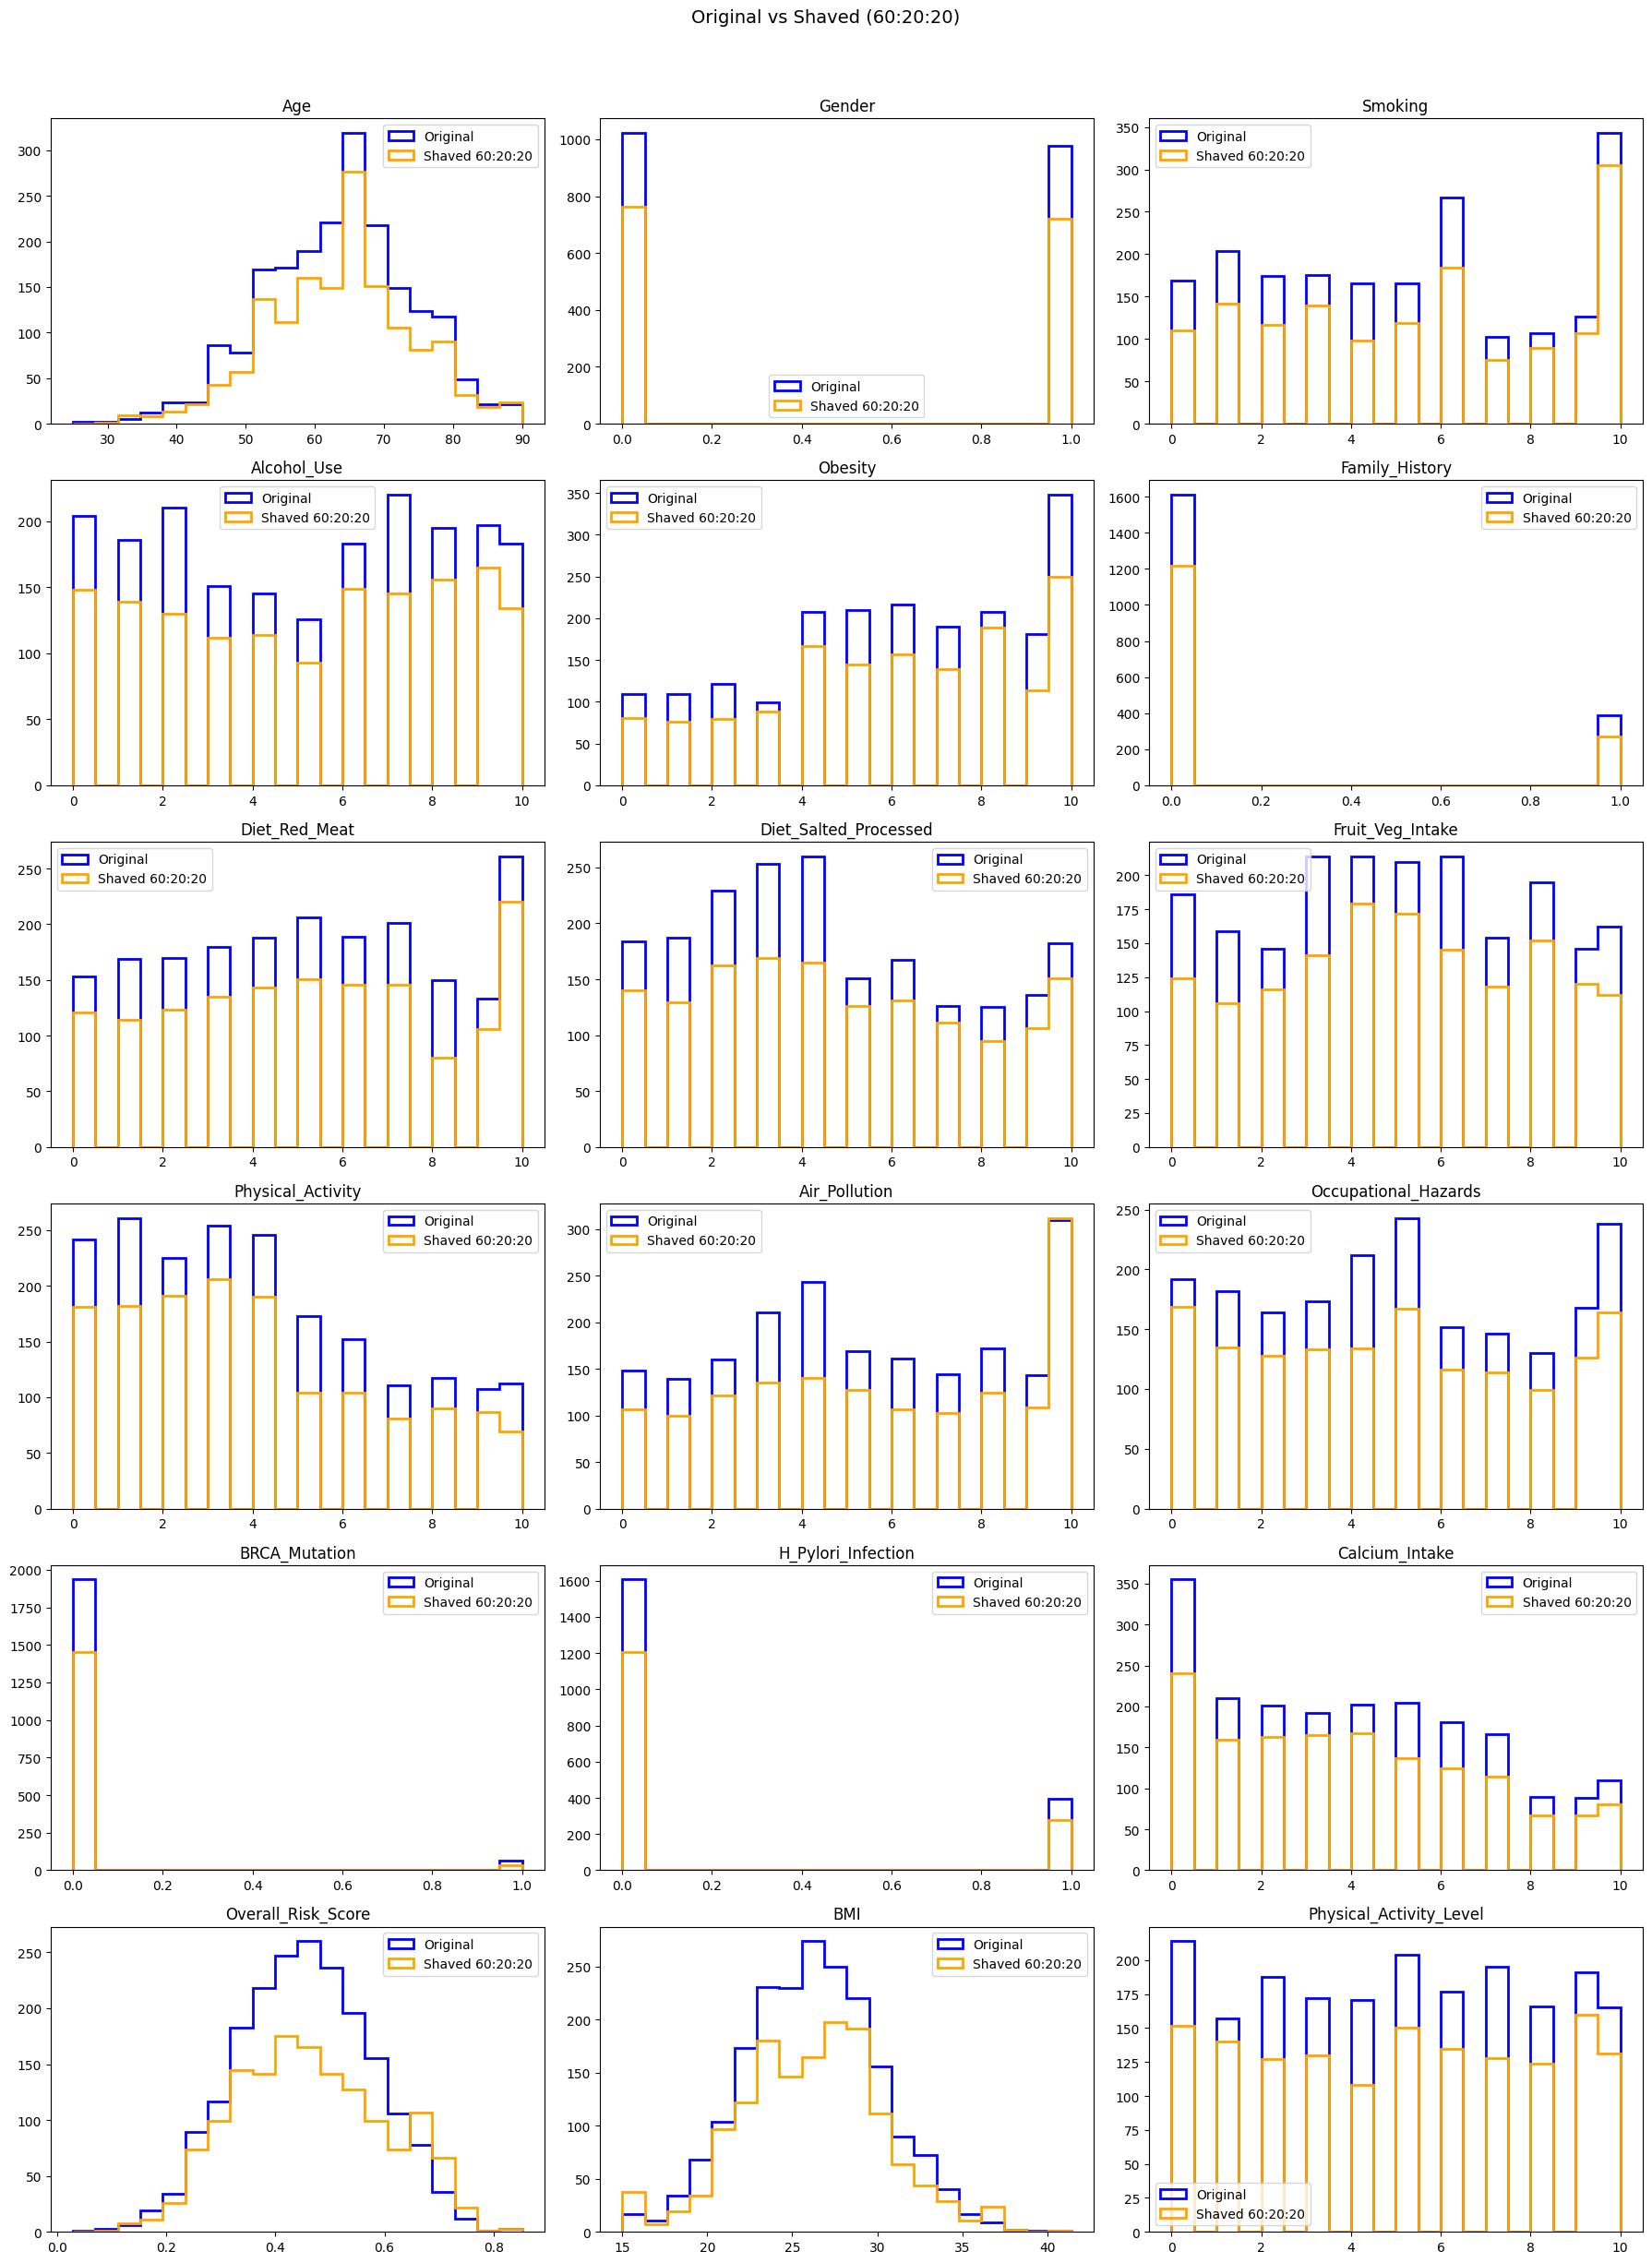

Saved shaved_comparison.png


In [6]:
# validate with og dataset
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt

# Load both
df_original = pd.read_csv("cancer-risk-factors.csv")
df_shaved   = pd.read_csv("cancer-risk-factors-shaved-60-20-20.csv")

print("=== Shape ===")
print(f"Original: {df_original.shape}")
print(f"Shaved:   {df_shaved.shape}")

print("\n=== Risk Level Distribution ===")
print("Original:")
print(df_original["Risk_Level"].value_counts(normalize=True).round(3))
print("\nShaved (60:20:20):")
print(df_shaved["Risk_Level"].value_counts(normalize=True).round(3))

print("\n=== Cancer Type Distribution ===")
print("Original:")
print(df_original["Cancer_Type"].value_counts(normalize=True).round(3))
print("\nShaved:")
print(df_shaved["Cancer_Type"].value_counts(normalize=True).round(3))

# Numeric columns
num_cols = [
    "Age", "Gender", "Smoking", "Alcohol_Use", "Obesity",
    "Family_History", "Diet_Red_Meat", "Diet_Salted_Processed",
    "Fruit_Veg_Intake", "Physical_Activity", "Air_Pollution",
    "Occupational_Hazards", "BRCA_Mutation", "H_Pylori_Infection",
    "Calcium_Intake", "Overall_Risk_Score", "BMI",
    "Physical_Activity_Level"
]

# Statistical comparison
print("\n=== Statistical Comparison ===")
print(f"{'Feature':<25} {'Orig Mean':>10} {'Shaved Mean':>12} {'Orig SD':>10} {'Shaved SD':>10}")
print("-" * 70)
for col in num_cols:
    print(f"{col:<25} "
          f"{df_original[col].mean():>10.3f} "
          f"{df_shaved[col].mean():>12.3f} "
          f"{df_original[col].std():>10.3f} "
          f"{df_shaved[col].std():>10.3f}")

# KS Test
print("\n=== KS Test (p > 0.05 = similar) ===")
for col in num_cols:
    stat, p = ks_2samp(df_original[col], df_shaved[col])
    status = "✓ similar" if p > 0.05 else "✗ different"
    print(f"{col:<25} p={p:.4f}  {status}")

# Histograms
n_cols = 3
n_rows = int(np.ceil(len(num_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    combined = pd.concat([df_original[col], df_shaved[col]])
    bins = np.linspace(combined.min(), combined.max(), 21)
    axes[i].hist(df_original[col], bins=bins, color='blue',
                 label='Original', histtype='step', linewidth=2)
    axes[i].hist(df_shaved[col], bins=bins, color='orange',
                 label='Shaved 60:20:20', histtype='step', linewidth=2)
    axes[i].set_title(col)
    axes[i].legend()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Original vs Shaved (60:20:20)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("shaved_comparison.png", bbox_inches='tight', dpi=150)
plt.show()
print("Saved shaved_comparison.png")